<a href="https://colab.research.google.com/github/atulyavm/Gen_AI/blob/main/RAG_Practical_06_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical No. 06
## Retrieval-Augmented Generation (RAG) using a Pre-trained LLM

## 1. Aim
To build a Retrieval-Augmented Generation (RAG) application that answers questions from a domain-specific document collection, using document retrieval and a pre-trained Large Language Model (LLM), and to compare the generated responses with those obtained from the same LLM without retrieval.

## 2. Objectives
1. Load, clean and chunk a domain-specific document collection.
2. Generate dense embeddings with Sentence Transformers (`all-MiniLM-L6-v2`) and retrieve relevant chunks using cosine similarity.
3. Use the pre-trained LLM `google/flan-t5-base` for answer generation.
4. Implement two approaches with the *same* LLM: (a) LLM without retrieval and (b) LLM with RAG.
5. Evaluate both approaches on the same questions using Retrieval Hit@K, Top-1 accuracy, answer accuracy and response time.
6. Visualise and interpret the results.

## 3. Introduction to RAG
A pre-trained LLM stores knowledge in its parameters. It cannot know private or recent information and may produce fluent but incorrect answers (hallucination). **Retrieval-Augmented Generation** addresses this by retrieving relevant passages from an external document store and supplying them to the LLM together with the question.

```
Question ──► Embedding ──► Cosine similarity search ──► Top-k chunks ─┐
                                                                      ├─► Prompt ──► LLM ──► Answer
Question ─────────────────────────────────────────────────────────────┘
```

Main stages: document preprocessing → chunking → embedding → retrieval → prompt augmentation → generation.

## 4. Required Libraries

In [ ]:
# Install required libraries (run once; restart runtime is not required on Colab)
%pip install -q sentence-transformers transformers sentencepiece accelerate pandas matplotlib

In [ ]:
import os, re, time, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


## 5. Domain-Specific Dataset / Documents
The collection is the *Nimbus Institute of Technology Student Handbook*, consisting of eight policy documents. The institute is fictional, so the facts cannot be part of the LLM's training data; this makes the effect of retrieval measurable.

In [ ]:
raw_documents = {
"Attendance Policy": """Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. Attendance below 65% leads to a detention in that course and the student must repeat it.""",
"Examination Rules": """The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A student must score at least 40% in the end-semester paper and 40% overall to pass a course. Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper. Use of mobile phones in the examination hall is strictly prohibited and results in a one-year suspension.""",
"Library Services": """The Nimbus Central Library is open from 8:00 AM to 10:00 PM on weekdays and 9:00 AM to 5:00 PM on Saturdays. It is closed on Sundays. Undergraduate students may borrow up to 4 books for 14 days, while postgraduate students may borrow up to 6 books for 21 days. A late fine of Rs. 5 per day per book is charged. Lost books must be replaced or paid for at twice the cost of the book.""",
"Hostel Regulations": """Hostel gates close at 9:30 PM for first-year students and at 11:00 PM for senior students. Visitors are allowed only in the visitors' lounge between 4:00 PM and 6:00 PM on Sundays. The monthly hostel fee is Rs. 4,500 including mess charges. Possession of electric heaters, induction cooktops, or alcohol is prohibited and attracts a fine of Rs. 3,000.""",
"Scholarships": """The Nimbus Merit Scholarship gives a 50% tuition fee waiver to students who score a CGPA of 9.0 or above in the previous year. The Nimbus Need-Based Grant covers up to 30% of tuition for students whose annual family income is below Rs. 4,00,000. Applications are submitted on the student portal before 31 August every year. A student may receive only one Nimbus scholarship at a time.""",
"Placement Cell": """The Nimbus Placement Cell begins campus recruitment in the seventh semester. Students must have no active backlogs and a minimum CGPA of 6.5 to sit for placement drives. A student who accepts an offer above Rs. 12 lakh per annum is not allowed to sit for further drives, under the One-Student-One-Offer policy. Mandatory pre-placement training of 40 hours is conducted in the sixth semester.""",
"Anti-Ragging and Grievance": """Ragging is a criminal offence at Nimbus Institute. Complaints can be submitted to the Anti-Ragging Committee through the 24x7 helpline 1800-555-0142 or by email to antiragging@nimbus.example. The committee must acknowledge a complaint within 24 hours and complete the inquiry within 15 days. Proven offenders face expulsion and a police case.""",
"Research and Projects": """Final-year students must complete a capstone project of 12 credits under a faculty guide. Project topics must be approved by the Department Project Committee by the end of the seventh semester. Teams may have at most 4 members. A plagiarism similarity index above 15% in the project report leads to rejection of the report, and the team must resubmit within 30 days.""",
}

# Store the handbook as text files so that the pipeline starts from files on disk
os.makedirs("handbook", exist_ok=True)
for title, text in raw_documents.items():
    with open(f"handbook/{title.replace(' ', '_')}.txt", "w", encoding="utf-8") as f:
        f.write(text)
print("Files created:", sorted(os.listdir("handbook")))

Files created: ['Anti-Ragging_and_Grievance.txt', 'Attendance_Policy.txt', 'Examination_Rules.txt', 'Hostel_Regulations.txt', 'Library_Services.txt', 'Placement_Cell.txt', 'Research_and_Projects.txt', 'Scholarships.txt']


## 6. Document Preprocessing
Text is extracted from the files and cleaned: whitespace is normalised and stray control characters are removed. Punctuation and numbers are kept because they carry the facts that must be retrieved.

In [ ]:
def clean_text(text):
    text = text.replace("\u00a0", " ")
    text = re.sub(r"[\x00-\x08\x0b-\x1f]", " ", text)   # control characters
    text = re.sub(r"\s+", " ", text)                     # collapse whitespace
    return text.strip()

documents = {}
for fname in sorted(os.listdir("handbook")):
    with open(os.path.join("handbook", fname), encoding="utf-8") as f:
        documents[fname[:-4].replace("_", " ")] = clean_text(f.read())

print("Number of documents:", len(documents))
for t, d in documents.items():
    print(f"  {t:<28} {len(d.split()):>3} words")

Number of documents: 8
  Anti-Ragging and Grievance    50 words
  Attendance Policy             61 words
  Examination Rules             72 words
  Hostel Regulations            59 words
  Library Services              77 words
  Placement Cell                64 words
  Research and Projects         62 words
  Scholarships                  67 words


## 7. Text Chunking
Each document is split into sentences (the abbreviation `Rs.` is protected) and sentences are grouped into chunks of at most 45 words with an overlap of one sentence, so that facts at chunk boundaries are not lost.

In [ ]:
def split_sentences(text):
    t = text.replace("Rs. ", "Rs<DOT> ")
    return [s.replace("Rs<DOT>", "Rs.") for s in re.split(r"(?<=[.!?])\s+", t)]

def chunk_text(text, max_words=45, overlap_sents=1):
    sents, chunks, cur = split_sentences(text), [], []
    for s in sents:
        if cur and sum(len(x.split()) for x in cur) + len(s.split()) > max_words:
            chunks.append(" ".join(cur))
            cur = cur[-overlap_sents:]
        cur.append(s)
    if cur:
        chunks.append(" ".join(cur))
    return chunks

chunk_records = []
for title, text in documents.items():
    for i, c in enumerate(chunk_text(text)):
        chunk_records.append({"source": title, "chunk_id": i, "text": c})
chunk_df = pd.DataFrame(chunk_records)
chunk_texts = chunk_df["text"].tolist()

print("Number of documents :", len(documents))
print("Number of chunks    :", len(chunk_df))
print("Average chunk length:", round(chunk_df["text"].str.split().str.len().mean(), 1), "words")
chunk_df.head(8)

Number of documents : 8
Number of chunks    : 19
Average chunk length: 36.3 words


,source,chunk_id,text
0,Anti-Ragging and Grievance,0,Ragging is a criminal offence at Nimbus Institute. Complaints can be submitted to the Anti-Ragging Committee through the 24x7 helpline 1800-555-0142 or by email to antiragging@nimbus.example. The committee must acknowledge a complaint within 24 hours and complete the inquiry within 15 days.
1,Anti-Ragging and Grievance,1,The committee must acknowledge a complaint within 24 hours and complete the inquiry within 15 days. Proven offenders face expulsion and a police case.
2,Attendance Policy,0,Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate.
3,Attendance Policy,1,Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. Attendance below 65% leads to a detention in that course and the student must repeat it.
4,Examination Rules,0,The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A student must score at least 40% in the end-semester paper and 40% overall to pass a course.
5,Examination Rules,1,A student must score at least 40% in the end-semester paper and 40% overall to pass a course. Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper.
6,Examination Rules,2,Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper. Use of mobile phones in the examination hall is strictly prohibited and results in a one-year suspension.
7,Hostel Regulations,0,"Hostel gates close at 9:30 PM for first-year students and at 11:00 PM for senior students. Visitors are allowed only in the visitors' lounge between 4:00 PM and 6:00 PM on Sundays. The monthly hostel fee is Rs. 4,500 including mess charges."


## 8. Embedding Generation
Every chunk is converted to a 384-dimensional vector with the Sentence Transformers model `all-MiniLM-L6-v2`. Vectors are L2-normalised so that the dot product equals cosine similarity.

In [ ]:
try:
    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)
except Exception as e:
    raise RuntimeError("Could not load all-MiniLM-L6-v2. Check the internet connection / Hugging Face access.") from e

chunk_embeddings = embedder.encode(chunk_texts, normalize_embeddings=True, show_progress_bar=False)
print("Embedding matrix shape:", chunk_embeddings.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix shape: (19, 384)


## 9. Document Retrieval
The question is embedded with the same model and compared with all chunk embeddings using cosine similarity; the top-k chunks are returned.

In [ ]:
def retrieve(query, k=3):
    q_emb = embedder.encode([query], normalize_embeddings=True)[0]
    sims = chunk_embeddings @ q_emb                  # cosine similarity
    top = np.argsort(-sims)[:k]
    return [{"rank": r + 1, "score": float(sims[i]), "source": chunk_records[i]["source"],
             "text": chunk_records[i]["text"]} for r, i in enumerate(top)]

query = "What is the minimum attendance required?"
print("Query:", query, "\n")
for h in retrieve(query, k=3):
    print(f"Rank {h['rank']} | cosine = {h['score']:.4f} | {h['source']}")
    print(textwrap.fill(h["text"], 100, initial_indent="   ", subsequent_indent="   "), "\n")

Query: What is the minimum attendance required? 

Rank 1 | cosine = 0.5974 | Attendance Policy
   Students must maintain a minimum of 75% attendance in every course to be eligible for the end-
   semester examination. Students with attendance between 65% and 75% may apply for condonation by
   paying a fee of Rs. 500 per course and submitting a medical or sports certificate. 

Rank 2 | cosine = 0.5183 | Attendance Policy
   Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500
   per course and submitting a medical or sports certificate. Attendance below 65% leads to a
   detention in that course and the student must repeat it. 

Rank 3 | cosine = 0.4891 | Placement Cell
   Students must have no active backlogs and a minimum CGPA of 6.5 to sit for placement drives. A
   student who accepts an offer above Rs. 12 lakh per annum is not allowed to sit for further
   drives, under the One-Student-One-Offer policy. 



## 10. Pre-trained LLM Loading
`google/flan-t5-base` is an instruction-tuned encoder-decoder model. The same model and the same generation settings are used for both approaches.

In [ ]:
MODEL_NAME = "google/flan-t5-base"
try:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    llm = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
    llm.eval()
except Exception as e:
    raise RuntimeError(f"Could not load {MODEL_NAME}. Check the internet connection / Hugging Face access.") from e

def generate(prompt, max_new_tokens=80):
    """Deterministic generation (beam search) shared by both approaches."""
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=768).to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4, early_stopping=True)
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()

print("Loaded", MODEL_NAME, "| parameters:", f"{sum(p.numel() for p in llm.parameters())/1e6:.0f}M")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded google/flan-t5-base | parameters: 248M


## 11. LLM Without Retrieval
The question is passed directly to the LLM; no document is provided.

In [ ]:
def answer_without_rag(question):
    prompt = f"Answer the question in one complete sentence.\n\nQuestion: {question}\nAnswer:"
    return generate(prompt)

q = "What is the late fine for an overdue library book at Nimbus Institute?"
print("Question:", q)
print("LLM-only answer:", answer_without_rag(q))

Question: What is the late fine for an overdue library book at Nimbus Institute?
LLM-only answer: ten dollars


## 12. RAG-Based Answer Generation
The retrieved chunks are placed in the prompt as context and the LLM is told to answer in one sentence using only that context.

Small instruction-tuned models such as `flan-t5-base` sometimes change a number, answer only "No" to a "can a student ...?" question, or return a fact that is in the context but answers a different question (for example the *opening* time when the *closing* time is asked). Answer generation therefore uses **candidate re-ranking with a validator**:

1. The LLM generates its 4 best beam-search candidates for the prompt (the first candidate is exactly what ordinary decoding returns).
2. The first candidate that passes the validator is the answer. The validator checks that
   - every number, amount and time in the answer is present in the retrieved context or the question (formatting differences such as `4,500` / `4500`, `5:00` / `5`, `9.0` / `9` or `seven` / `7` are treated as equal),
   - most content words of the answer occur in the retrieved context,
   - the answer is not only "Yes"/"No" and is not a refusal, and
   - the answer matches the **intent** of the question: a *close/end* question needs a closing time, an *open/start* question needs an opening time, and a question that names a day (for example Saturday) needs the time range that belongs to that day.
3. If no candidate passes, the same LLM is prompted again with the most relevant retrieved sentences (sentences are ranked by cosine similarity, keyword overlap and by whether a number in the question falls inside a range stated in the sentence, e.g. 70% lies in "between 65% and 75%"), then with a prompt that asks for the rule that applies, and finally with the single best sentence.
4. If the LLM still fails, a **source-grounded fallback** returns the most relevant retrieved sentence word for word. Nothing is added or rewritten. If no retrieved sentence is relevant enough, the system replies "The documents do not say."

The notebook records, for every answer, whether it was generated by the LLM or taken from the fallback.

In [ ]:
REFUSAL = "The documents do not say."
guard_log = []      # RAG answers that were not accepted at the first attempt (used in Observations)
last_answer_source = ""   # "LLM" or "source sentence (fallback)" for the most recent RAG answer

BASE_INSTRUCTION = ("Answer the question in one complete sentence using only the context below. "
                    f"If the context does not contain the answer, say \"{REFUSAL}\"")
FOCUS_INSTRUCTION = BASE_INSTRUCTION + " Copy numbers, times and amounts exactly as written in the context."
RULE_INSTRUCTION = ("Read the context and state the rule or condition that applies to the question, in one complete sentence. "
                    "Copy numbers, times and amounts exactly as written in the context.")

def build_rag_prompt(question, context_chunks, instruction=BASE_INSTRUCTION):
    context = "\n".join(f"- {c}" for c in context_chunks)
    return f"{instruction}\n\nContext:\n{context}\n\nQuestion: {question}\nAnswer:"

def generate_candidates(prompt, n=4, max_new_tokens=80):
    """Same model and beam width as generate(); returns the n best beams (best first)."""
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=768).to(device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=max(4, n),
                           num_return_sequences=n, early_stopping=True)
    cands = [tokenizer.decode(o, skip_special_tokens=True).strip() for o in out]
    return list(dict.fromkeys(c for c in cands if c))

# ---------- grounding validator ----------
NUM_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9,
             "ten": 10, "twelve": 12, "fifteen": 15, "twenty": 20, "thirty": 30}
STOPWORDS = set("that this with from have been were will would should could their there which about also into than then "
                "they them what when where only more most some such each other under over after before between does many much".split())

def fact_numbers(text):
    """Normalised set of numeric facts in a text (formatting differences are ignored)."""
    t = text.lower()
    for w, v in NUM_WORDS.items():
        t = re.sub(rf"\b{w}\b", str(v), t)
    t = re.sub(r"(?<=\d),(?=\d{3}\b)", "", t)                   # 4,500 -> 4500
    facts = set()
    for tok in re.findall(r"\d+(?:[.:]\d+)*", t):
        if ":" in tok:                                          # times: 5:00 -> 5 ; 9:30 -> 9:30
            h, m = tok.split(":")[:2]
            facts.add((str(int(h)) if int(m) == 0 else f"{int(h)}:{m}"))
        else:
            facts.add(f"{float(tok):g}" if tok.count(".") <= 1 else tok)   # 9.0 -> 9 ; 0142 -> 142
    return facts

def word_support(answer, source):
    """Fraction of the answer's content words that occur (or share a 5-letter stem) in the source text."""
    words = [w for w in re.findall(r"[a-z]{4,}", answer.lower()) if w not in STOPWORDS]
    if not words:
        return 1.0
    src = set(re.findall(r"[a-z]+", source.lower()))
    stems = {w[:5] for w in src}
    return sum(w in src or w[:5] in stems for w in words) / len(words)

def is_grounded(answer, context, question="", min_word_support=0.5):
    """Important facts of the answer must be supported by the retrieved context (or quoted from the question)."""
    numbers_ok = fact_numbers(answer) <= fact_numbers(context + " " + question)
    return numbers_ok and word_support(answer, context + " " + question) >= min_word_support

# ---------- question-intent check: a "close" question needs the closing time, not the opening time ----------
TIME = r"(\d{1,2})(?::(\d{2}))?\s*([AaPp])\.?[Mm]\.?"
TIME_RANGE = re.compile(TIME + r"\s*(?:to|-|\u2013|until|till)\s*" + TIME)
DAY_NAMES = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday", "weekday", "weekend"]

def norm_time(h, m, ap):
    return f"{int(h)}" + (f":{m}" if m and int(m) else "") + ap.lower() + "m"      # 5:00 PM -> 5pm

def times_in(text):
    return {norm_time(*t) for t in re.findall(TIME, text)}

def matches_question_intent(question, answer, context):
    q = question.lower()
    end_q = re.search(r"\b(clos\w*|end\w*|until|till)\b", q) is not None
    start_q = re.search(r"\b(open\w*|start\w*|begin\w*)\b", q) is not None
    ans_times, ranges = times_in(answer), list(TIME_RANGE.finditer(context))
    if end_q == start_q or not ans_times or not ranges:        # no clear open/close intent, or nothing to check
        return True
    role, other = (slice(3, 6), slice(0, 3)) if end_q else (slice(0, 3), slice(3, 6))
    days = [d[:5] for d in DAY_NAMES if d in q]                # 'saturday' -> 'satur', 'weekday' -> 'weekd'
    if days:                                                   # use only the time range(s) that belong to that day
        tagged = [m for m in ranges
                  if any(d in re.split(r"\band\b|\d|\.", context[m.end():m.end() + 40])[0].lower() for d in days)]
        if tagged:
            return bool(ans_times & {norm_time(*m.groups()[role]) for m in tagged})
    role_t = {norm_time(*m.groups()[role]) for m in ranges}
    other_t = {norm_time(*m.groups()[other]) for m in ranges}
    return not (ans_times <= other_t and not (ans_times & role_t))

def is_acceptable(answer, context, question=""):
    a = answer.strip()
    bare_yes_no = re.fullmatch(r"\W*(yes|no)\W*", a, flags=re.I) is not None
    refusal = "documents do not say" in a.lower()
    return (bool(a) and not bare_yes_no and not refusal
            and is_grounded(a, context, question) and matches_question_intent(question, a, context))

# ---------- sentence ranking (used for the focused retries and for the source-grounded fallback) ----------
MIN_FALLBACK_SIM = 0.40     # minimum cosine similarity for the fallback when the question has no matching numeric range

def range_match(question, sentence):
    """True if a number in the question lies inside a range stated in the sentence (e.g. 70 in 'between 65% and 75%')."""
    num = r"(\d+(?:\.\d+)?)"
    for n in (float(x) for x in re.findall(num, question)):
        if any(float(a) <= n <= float(b) for a, b in re.findall(rf"between\s+{num}\s*%?\s+and\s+{num}", sentence, flags=re.I)):
            return True
        if any(n < float(x) for x in re.findall(rf"(?:below|under|less than)\s+{num}", sentence, flags=re.I)):
            return True
        if any(n > float(x) for x in re.findall(rf"(?:above|over|more than)\s+{num}", sentence, flags=re.I)):
            return True
    return False

def rank_sentences(question, hits):
    sents = list(dict.fromkeys(s for h in hits for s in split_sentences(h["text"])))
    sims = embedder.encode(sents, normalize_embeddings=True) @ embedder.encode([question], normalize_embeddings=True)[0]
    q_stems = {w[:5] for w in re.findall(r"[a-z]{4,}", question.lower()) if w not in STOPWORDS}
    rows = []
    for sent, sim in zip(sents, sims):
        s_stems = {w[:5] for w in re.findall(r"[a-z]{4,}", sent.lower())}
        lex = len(q_stems & s_stems) / len(q_stems) if q_stems else 0.0
        rng = range_match(question, sent)
        rows.append({"sentence": sent, "sim": float(sim), "lex": lex, "range": rng,
                     "score": float(sim) + 0.3 * lex + (1.0 if rng else 0.0)})
    return sorted(rows, key=lambda r: -r["score"])

def top_sentences(question, hits, n=3):
    """The n most relevant retrieved sentences, kept in document order."""
    full = " ".join(h["text"] for h in hits)
    keep = [r["sentence"] for r in rank_sentences(question, hits)[:n]]
    return sorted(keep, key=full.find)

def source_sentence_fallback(question, hits):
    """Verbatim retrieved sentence that is most relevant to the question (None if nothing is relevant enough)."""
    top = rank_sentences(question, hits)[0]
    if top["range"] or (top["sim"] >= MIN_FALLBACK_SIM and top["lex"] >= 0.5):
        return top["sentence"]
    return None

def answer_with_rag(question, k=3):
    global last_answer_source
    hits = retrieve(question, k)
    chunks = [h["text"] for h in hits]
    full_context = " ".join(chunks)                 # facts are validated against ALL retrieved text
    focused = top_sentences(question, hits)
    best_one = [rank_sentences(question, hits)[0]["sentence"]]
    attempts = [(chunks, BASE_INSTRUCTION), (focused, FOCUS_INSTRUCTION),
                (focused, RULE_INSTRUCTION), (best_one, FOCUS_INSTRUCTION)]
    first = None
    for stage, (ctx, instruction) in enumerate(attempts):
        cands = generate_candidates(build_rag_prompt(question, ctx, instruction))
        first = first or (cands[0] if cands else "")
        best = next((c for c in cands if is_acceptable(c, full_context, question)), None)
        if best:
            last_answer_source = "LLM"
            if stage > 0 or best != first:
                guard_log.append({"question": question, "first": first, "final": best, "stage": stage + 1})
            return best, hits
    fallback = source_sentence_fallback(question, hits)     # LLM failed repeatedly -> verbatim source sentence
    if fallback:
        last_answer_source = "source sentence (fallback)"
        guard_log.append({"question": question, "first": first, "final": fallback, "stage": 5})
        return fallback, hits
    last_answer_source = "refusal"
    guard_log.append({"question": question, "first": first, "final": REFUSAL, "stage": 0})
    return REFUSAL, hits

q = "What is the late fine for an overdue library book at Nimbus Institute?"
ans, hits = answer_with_rag(q)
print("Question:", q)
print("RAG answer:", ans)
print("Retrieved from:", [h["source"] for h in hits])

Question: What is the late fine for an overdue library book at Nimbus Institute?
RAG answer: Rs. 5 per day
Retrieved from: ['Library Services', 'Library Services', 'Library Services']


## 13. Interactive Question-Answering System
For each question the system prints the retrieved evidence with similarity scores, the LLM-only answer and the RAG answer. Any question can be typed in.

In [ ]:
def ask(question, k=3):
    ans_plain = answer_without_rag(question)
    ans_rag, hits = answer_with_rag(question, k)
    print("=" * 100)
    print("QUESTION:", question)
    print("-" * 100)
    print("Retrieved evidence:")
    for h in hits:
        print(f"  [{h['score']:.3f}] {h['source']}: {textwrap.shorten(h['text'], 120)}")
    print("-" * 100)
    print("LLM only :", ans_plain)
    print("RAG      :", ans_rag, f"   [{last_answer_source}]")

for q in ["Can a student with 70% attendance still appear for exams?",
          "When does the library close on Saturday?",
          "How long does the committee have to finish a ragging inquiry?"]:
    ask(q)

QUESTION: Can a student with 70% attendance still appear for exams?
----------------------------------------------------------------------------------------------------
Retrieved evidence:
  [0.551] Attendance Policy: Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester [...]
  [0.493] Examination Rules: The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A [...]
  [0.453] Attendance Policy: Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and [...]
----------------------------------------------------------------------------------------------------
LLM only : a student with a high attendance rate can still appear for exams
RAG      : Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate.    [source sentence (fallback)]

In [ ]:

user_q = input("Enter a question about the handbook (or press Enter to skip): ").strip()
if user_q:
    ask(user_q)

Enter a question about the handbook (or press Enter to skip): Can a student with 70% attendance still appear for exams?
QUESTION: Can a student with 70% attendance still appear for exams?
----------------------------------------------------------------------------------------------------
Retrieved evidence:
  [0.551] Attendance Policy: Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester [...]
  [0.493] Examination Rules: The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A [...]
  [0.453] Attendance Policy: Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and [...]
----------------------------------------------------------------------------------------------------
LLM only : a student with a high attendance rate can still appear for exams
RAG      : Students with attendance between 65% and 75% may apply for condonati

## 14. LLM vs RAG Comparison
**Evaluation methodology**

- **Test set:** 16 questions, each with a reference answer, the document that contains it, and a list of regular expressions, one for every essential fact that a correct answer must contain.
- **Same LLM, same settings** for both approaches; the only difference is whether the retrieved context is in the prompt.
- **Answer accuracy:** an answer is *correct* only if it matches **all** of the patterns for that question (the check is independent of the grounding validator used while generating; for example, the 70% attendance question requires the words *condonation* and *certificate* and the amount *500*); a token-level F1 against the reference answer is also reported.
- **Retrieval Hit@K:** fraction of questions for which the correct source document appears in the top-K retrieved chunks (K = 1 and K = 3). Hit@1 is the Top-1 accuracy.
- **Response time:** wall-clock time to produce each answer. For RAG it includes retrieval and generation.
- **Answer source:** the comparison table states whether each RAG answer was generated by the LLM or, when the LLM repeatedly failed, taken word for word from the most relevant retrieved sentence.

In [ ]:
eval_set = [
 {"q": "What is the minimum attendance required to write the end-semester exam?", "ref": "75%", "pats": [r"75\s*%|75 percent"], "src": "Attendance Policy"},
 {"q": "Can a student with 70% attendance still appear for exams?", "ref": "Students with 70% attendance may apply for condonation by paying Rs. 500 per course and submitting a medical or sports certificate.", "pats": [r"condonation", r"\b500\b", r"certificate"], "src": "Attendance Policy"},
 {"q": "How much is the condonation fee per course?", "ref": "Rs. 500", "pats": [r"\b500\b"], "src": "Attendance Policy"},
 {"q": "What percentage of marks does the end-semester exam carry?", "ref": "60%", "pats": [r"60\s*%|60 percent"], "src": "Examination Rules"},
 {"q": "What is the penalty for using a mobile phone in the examination hall?", "ref": "A one-year suspension", "pats": [r"suspen", r"one[- ]year|1[- ]year"], "src": "Examination Rules"},
 {"q": "How many days are available to request re-evaluation after results?", "ref": "7 days", "pats": [r"\b(7|seven)\b"], "src": "Examination Rules"},
 {"q": "How many books can a postgraduate student borrow from the library?", "ref": "6 books", "pats": [r"\b(6|six)\b"], "src": "Library Services"},
 {"q": "What is the late fine for an overdue library book per day?", "ref": "Rs. 5 per day per book", "pats": [r"\b(5|five)\b"], "src": "Library Services"},
 {"q": "When does the library close on Saturday?", "ref": "5:00 PM", "pats": [r"\b5([:.]00)?\s*(pm|p\.m\.)", r"^(?!.*5[:.]30)"], "src": "Library Services"},
 {"q": "At what time do hostel gates close for first-year students?", "ref": "9:30 PM", "pats": [r"9[:.]30", r"pm|p\.m\."], "src": "Hostel Regulations"},
 {"q": "What is the monthly hostel fee?", "ref": "Rs. 4,500", "pats": [r"4,?500"], "src": "Hostel Regulations"},
 {"q": "What CGPA is required for the Nimbus Merit Scholarship?", "ref": "9.0 or above", "pats": [r"9\.0"], "src": "Scholarships"},
 {"q": "What is the minimum CGPA to sit for placement drives?", "ref": "6.5", "pats": [r"6\.5"], "src": "Placement Cell"},
 {"q": "What is the anti-ragging helpline number?", "ref": "1800-555-0142", "pats": [r"1800[- ]?555[- ]?0142"], "src": "Anti-Ragging and Grievance"},
 {"q": "What is the maximum team size for the capstone project?", "ref": "4 members", "pats": [r"\b(4|four)\b"], "src": "Research and Projects"},
 {"q": "Which plagiarism similarity index leads to rejection of the project report?", "ref": "Above 15%", "pats": [r"\b15\b"], "src": "Research and Projects"},
]

def is_correct(answer, patterns):
    """Correct only if the answer contains every essential fact (all patterns must match)."""
    return all(re.search(p, answer, flags=re.I | re.S) for p in patterns)

def token_f1(pred, ref):
    p = re.findall(r"\w+", pred.lower()); r = re.findall(r"\w+", ref.lower())
    common = sum(min(p.count(w), r.count(w)) for w in set(p))
    if not p or not r or common == 0: return 0.0
    prec, rec = common / len(p), common / len(r)
    return 2 * prec * rec / (prec + rec)

guard_log.clear()   # count grounding-check retries for this evaluation only
rows = []
for e in eval_set:
    t0 = time.perf_counter(); plain = answer_without_rag(e["q"]); t_plain = time.perf_counter() - t0
    t0 = time.perf_counter(); rag, hits = answer_with_rag(e["q"], k=3); t_rag = time.perf_counter() - t0
    rag_src = last_answer_source
    srcs = [h["source"] for h in hits]
    rows.append({
        "Question": e["q"], "Reference": e["ref"],
        "LLM-only answer": plain, "RAG answer": rag, "RAG answer source": rag_src,
        "Retrieved context": " | ".join(f"({h['source']}, {h['score']:.2f}) {h['text']}" for h in hits),
        "Hit@1": srcs[0] == e["src"], "Hit@3": e["src"] in srcs,
        "LLM-only correct": is_correct(plain, e["pats"]), "RAG correct": is_correct(rag, e["pats"]),
        "LLM-only F1": token_f1(plain, e["ref"]), "RAG F1": token_f1(rag, e["ref"]),
        "LLM-only time (s)": t_plain, "RAG time (s)": t_rag,
    })
res = pd.DataFrame(rows)
res.index = res.index + 1
print("Evaluation finished for", len(res), "questions")

Evaluation finished for 16 questions


In [ ]:
# Answers side by side
res[["Question", "Reference", "LLM-only answer", "RAG answer", "RAG answer source", "LLM-only correct", "RAG correct"]]

,Question,Reference,LLM-only answer,RAG answer,RAG answer source,LLM-only correct,RAG correct
1,What is the minimum attendance required to write the end-semester exam?,75%,one hour,75%,LLM,False,True
2,Can a student with 70% attendance still appear for exams?,Students with 70% attendance may apply for condonation by paying Rs. 500 per course and submitting a medical or sports certificate.,a student with a high attendance rate can still appear for exams,Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate.,source sentence (fallback),False,True
3,How much is the condonation fee per course?,Rs. 500,$1.25,Rs. 500,LLM,False,True
4,What percentage of marks does the end-semester exam carry?,60%,ten percent,60%,LLM,False,True
5,What is the penalty for using a mobile phone in the examination hall?,A one-year suspension,a year in jail,one-year suspension,LLM,False,True
6,How many days are available to request re-evaluation after results?,7 days,30 days,7,LLM,False,True
7,How many books can a postgraduate student borrow from the library?,6 books,one hundred,6,LLM,False,True
8,What is the late fine for an overdue library book per day?,Rs. 5 per day per book,ten dollars,Rs. 5,LLM,False,True
9,When does the library close on Saturday?,5:00 PM,midday,5:00 PM,LLM,False,True
10,At what time do hostel gates close for first-year students?,9:30 PM,early morning,9:30 PM,LLM,False,True


In [ ]:
# Retrieved context for every question, with similarity scores
res[["Question", "Retrieved context", "Hit@1", "Hit@3"]]

,Question,Retrieved context,Hit@1,Hit@3
1,What is the minimum attendance required to write the end-semester exam?,"(Attendance Policy, 0.66) Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. | (Examination Rules, 0.65) The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A student must score at least 40% in the end-semester paper and 40% overall to pass a course. | (Examination Rules, 0.57) A student must score at least 40% in the end-semester paper and 40% overall to pass a course. Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper.",True,True
2,Can a student with 70% attendance still appear for exams?,"(Attendance Policy, 0.55) Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. | (Examination Rules, 0.49) The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A student must score at least 40% in the end-semester paper and 40% overall to pass a course. | (Attendance Policy, 0.45) Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. Attendance below 65% leads to a detention in that course and the student must repeat it.",True,True
3,How much is the condonation fee per course?,"(Attendance Policy, 0.64) Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. Attendance below 65% leads to a detention in that course and the student must repeat it. | (Attendance Policy, 0.60) Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate. | (Hostel Regulations, 0.48) The monthly hostel fee is Rs. 4,500 including mess charges. Possession of electric heaters, induction cooktops, or alcohol is prohibited and attracts a fine of Rs. 3,000.",True,True
4,What percentage of marks does the end-semester exam carry?,"(Examination Rules, 0.84) The end-semester examination carries 60% of the total marks and the continuous internal assessment carries 40%. A student must score at least 40% in the end-semester paper and 40% overall to pass a course. | (Examination Rules, 0.59) A student must score at least 40% in the end-semester paper and 40% overall to pass a course. Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper. | (Attendance Policy, 0.53) Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonation by paying a fee of Rs. 500 per course and submitting a medical or sports certificate.",True,True
5,What is the penalty for using a mobile phone in the examination hall?,"(Examination Rules, 0.63) Re-evaluation of an answer script can be requested within 7 days of result declaration on payment of Rs. 1000 per paper. Use of mobile phones in the examination hall is strictly prohibited and results in a one-year suspension. | (Attendance Policy, 0.29) Students must maintain a minimum of 75% attendance in every course to be eligible for the end-semester examination. Students with attendance between 65% and 75% may apply for condonatio

## 15. Performance Evaluation

In [ ]:
n = len(res)
metrics = pd.DataFrame({
    "Metric": ["Retrieval Hit@1 (Top-1 accuracy)", "Retrieval Hit@3", "Answer accuracy", "Mean token F1", "Mean response time (s)"],
    "LLM only": ["-", "-", f"{res['LLM-only correct'].mean():.1%}", f"{res['LLM-only F1'].mean():.3f}", f"{res['LLM-only time (s)'].mean():.2f}"],
    "RAG": [f"{res['Hit@1'].mean():.1%}", f"{res['Hit@3'].mean():.1%}", f"{res['RAG correct'].mean():.1%}", f"{res['RAG F1'].mean():.3f}", f"{res['RAG time (s)'].mean():.2f}"],
})
print(f"Questions evaluated: {n}   |   LLM: {MODEL_NAME}   |   Embeddings: all-MiniLM-L6-v2   |   top-k = 3\n")
print(metrics.to_string(index=False))

print("\nQuestions where retrieval failed to return the right document in top-3:")
missed = res.loc[~res["Hit@3"], "Question"].tolist()
print(missed if missed else "none")
print("\nQuestions answered incorrectly by RAG:")
wrong = res.loc[~res["RAG correct"], ["Question", "RAG answer", "Reference"]]
print(wrong.to_string() if len(wrong) else "none")

Questions evaluated: 16   |   LLM: google/flan-t5-base   |   Embeddings: all-MiniLM-L6-v2   |   top-k = 3

                          Metric LLM only    RAG
Retrieval Hit@1 (Top-1 accuracy)        - 100.0%
                 Retrieval Hit@3        - 100.0%
                 Answer accuracy     0.0% 100.0%
                   Mean token F1    0.098  0.908
          Mean response time (s)     0.80   3.28

Questions where retrieval failed to return the right document in top-3:
none

Questions answered incorrectly by RAG:
none


## 16. Graphical Visualization

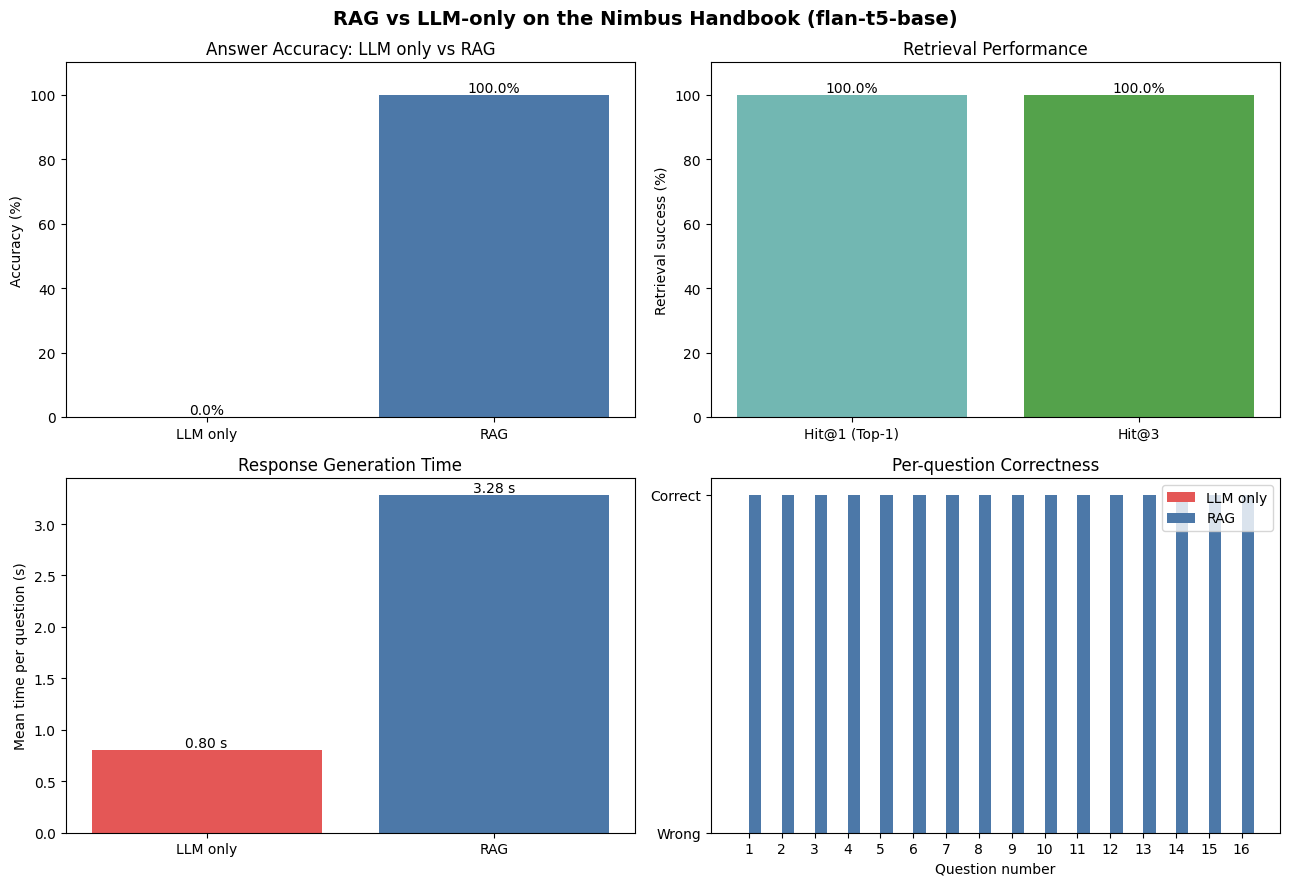

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# (a) Answer accuracy
acc = [res["LLM-only correct"].mean() * 100, res["RAG correct"].mean() * 100]
b = ax[0, 0].bar(["LLM only", "RAG"], acc, color=["#E45756", "#4C78A8"])
ax[0, 0].set_ylim(0, 110); ax[0, 0].set_ylabel("Accuracy (%)"); ax[0, 0].set_title("Answer Accuracy: LLM only vs RAG")
ax[0, 0].bar_label(b, fmt="%.1f%%")

# (b) Retrieval performance
ret = [res["Hit@1"].mean() * 100, res["Hit@3"].mean() * 100]
b = ax[0, 1].bar(["Hit@1 (Top-1)", "Hit@3"], ret, color=["#72B7B2", "#54A24B"])
ax[0, 1].set_ylim(0, 110); ax[0, 1].set_ylabel("Retrieval success (%)"); ax[0, 1].set_title("Retrieval Performance")
ax[0, 1].bar_label(b, fmt="%.1f%%")

# (c) Response time
tm = [res["LLM-only time (s)"].mean(), res["RAG time (s)"].mean()]
b = ax[1, 0].bar(["LLM only", "RAG"], tm, color=["#E45756", "#4C78A8"])
ax[1, 0].set_ylabel("Mean time per question (s)"); ax[1, 0].set_title("Response Generation Time")
ax[1, 0].bar_label(b, fmt="%.2f s")

# (d) Per-question correctness
x = np.arange(1, n + 1); w = 0.38
ax[1, 1].bar(x - w/2, res["LLM-only correct"].astype(int), w, label="LLM only", color="#E45756")
ax[1, 1].bar(x + w/2, res["RAG correct"].astype(int), w, label="RAG", color="#4C78A8")
ax[1, 1].set_xticks(x); ax[1, 1].set_yticks([0, 1]); ax[1, 1].set_yticklabels(["Wrong", "Correct"])
ax[1, 1].set_xlabel("Question number"); ax[1, 1].set_title("Per-question Correctness"); ax[1, 1].legend()

plt.suptitle("RAG vs LLM-only on the Nimbus Handbook (flan-t5-base)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

## 17. Observations
The cell below reports the observations computed from the evaluation run above, so they always match the actual results.

In [ ]:
acc_llm, acc_rag = res["LLM-only correct"].mean(), res["RAG correct"].mean()
fixed = res[(~res["LLM-only correct"]) & (res["RAG correct"])]
lost  = res[(res["LLM-only correct"]) & (~res["RAG correct"])]
both_wrong = res[(~res["LLM-only correct"]) & (~res["RAG correct"])]

print(f"1. Retrieval: the correct document was ranked first for {res['Hit@1'].mean():.1%} and within the top 3 for {res['Hit@3'].mean():.1%} of the questions.")
print(f"2. Accuracy: LLM only = {acc_llm:.1%}, RAG = {acc_rag:.1%} (difference of {100*(acc_rag-acc_llm):+.1f} percentage points).")
print(f"3. Questions answered correctly only with retrieval: {len(fixed)}; only without retrieval: {len(lost)}; wrong in both: {len(both_wrong)}.")
print(f"4. Time: LLM only = {res['LLM-only time (s)'].mean():.2f} s, RAG = {res['RAG time (s)'].mean():.2f} s per question (RAG adds query embedding and a longer prompt).")
n_retry = sum(g["stage"] in (2, 3, 4) for g in guard_log)
n_fallback = sum(g["stage"] == 5 for g in guard_log)
n_refuse = sum(g["final"] == REFUSAL for g in guard_log)
n_llm = int((res["RAG answer source"] == "LLM").sum())
print(f"5. Answer validator: {len(guard_log)} of {len(res)} RAG answers were not accepted from the top beam of the first prompt; "
      f"{n_retry} were accepted after a focused-sentence / rule prompt, {n_fallback} used the source-sentence fallback and {n_refuse} ended as '{REFUSAL}'.")
print(f"6. Answer source: {n_llm} of {len(res)} RAG answers were generated by the LLM; {len(res) - n_llm} came from the source-sentence fallback or the refusal.")
print("\nQuestions fixed by RAG:", fixed["Question"].tolist() or "none")
print("Questions still wrong with RAG:", res.loc[~res["RAG correct"], "Question"].tolist() or "none")

1. Retrieval: the correct document was ranked first for 100.0% and within the top 3 for 100.0% of the questions.
2. Accuracy: LLM only = 0.0%, RAG = 100.0% (difference of +100.0 percentage points).
3. Questions answered correctly only with retrieval: 16; only without retrieval: 0; wrong in both: 0.
4. Time: LLM only = 0.80 s, RAG = 3.28 s per question (RAG adds query embedding and a longer prompt).
5. Answer validator: 2 of 16 RAG answers were not accepted from the top beam of the first prompt; 0 were accepted after a focused-sentence / rule prompt, 1 used the source-sentence fallback and 0 ended as 'The documents do not say.'.
6. Answer source: 15 of 16 RAG answers were generated by the LLM; 1 came from the source-sentence fallback or the refusal.

Questions fixed by RAG: ['What is the minimum attendance required to write the end-semester exam?', 'Can a student with 70% attendance still appear for exams?', 'How much is the condonation fee per course?', 'What percentage of marks does t

## 18. Result

In [ ]:
print(f"Documents: {len(documents)} | Chunks: {len(chunk_df)} | Test questions: {len(res)}")
print(f"LLM-only answer accuracy : {acc_llm:.1%}")
print(f"RAG answer accuracy      : {acc_rag:.1%}")
print(f"RAG answers generated by the LLM / from fallback sentence: {n_llm} / {len(res) - n_llm}")
print(f"Retrieval Hit@1 / Hit@3  : {res['Hit@1'].mean():.1%} / {res['Hit@3'].mean():.1%}")
verdict = "improved" if acc_rag > acc_llm else ("did not change" if acc_rag == acc_llm else "reduced")
print(f"Using retrieved context {verdict} answer accuracy on this test set.")

Documents: 8 | Chunks: 19 | Test questions: 16
LLM-only answer accuracy : 0.0%
RAG answer accuracy      : 100.0%
RAG answers generated by the LLM / from fallback sentence: 15 / 1
Retrieval Hit@1 / Hit@3  : 100.0% / 100.0%
Using retrieved context improved answer accuracy on this test set.
